# Exposición de los activos a las variables de estado

**Objetivo:** medir cómo se mueve cada activo de la cartera cuando se mueven las variables de estado. El resultado es la **matriz de exposición** (`exposiciones.csv`), que usan el resumen diario, el informe semanal y las estrategias.

**Datos:** semanales (cierre del viernes), activos en **euros** como los vive la cartera (conversión con FRED DEXUSEU, alineada con el cierre de EE. UU.; ver `datos.cambio_eurusd`), rentabilidad logarítmica; cambios de las variables **estandarizados** ($z$), así que cada coeficiente es «% de rentabilidad semanal ante +1σ».

**Dos lecturas distintas, cada una para un uso:**

| Lectura | Cálculo | Pregunta que responde | Uso |
|---|---|---|---|
| **Efecto típico** | regresión simple del activo sobre una variable: $\gamma_k = \operatorname{cov}(r, z_k)/\operatorname{var}(z_k)$ | «cuando esta variable sube 1σ, con lo que suele moverse a la vez el resto, ¿qué hace el activo?» | noticias (una noticia nunca mueve una sola variable), lectura humana de la matriz |
| **Exposición directa** | regresión múltiple: $\beta_k$ con las demás variables fijas | «¿qué parte del movimiento es de esta variable y no de las otras?» | atribución del informe semanal ($\sum_j \beta_j z_j$, todas las variables a la vez) |

Se relacionan por $\gamma_k = \sum_j \beta_j\,\rho_{jk}$ (con $z$ estandarizadas): con variables correlacionadas pueden diferir mucho e incluso cambiar de signo (EUR/USD y dólar amplio: $\rho \approx -0{,}8$). Usar $\beta_k$ para una noticia aislada era un error de método (revisión del 01/11/2026).

**Inferencia:** t de Newey-West (4 rezagos). Umbral de lectura $|t| > 2{,}58$ (1 %): con 72 pares activo-variable, al 5 % saldrían unas 3-4 relaciones «significativas» por azar. Estabilidad: misma estimación antes y después de 2022 (cambio de régimen de inflación).

**Límites:** relaciones contemporáneas: describen el riesgo que se lleva, no predicen rentabilidades. Valoración y sentimiento no entran (demasiado lentas / sin serie diaria gratuita).

In [1]:

from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nucleo.backtest import mco
from nucleo.datos import precios, variable
from nucleo.rutas import MATRIZ
from nucleo.universo import ACTIVOS, CORTE_REGIMEN, INICIO, VARIABLES

VARIABLES = {n: v for n, v in VARIABLES.items() if v[3]}  # solo las que entran en la regresión
FICHERO_MATRIZ = MATRIZ  # analisis/exposiciones.csv (nucleo/rutas.py)
UMBRAL_T = 2.58
pd.set_option("display.width", 200)

## Datos

In [2]:
def semanal(s):
    return s.resample("W-FRI").last()


precios_activos = pd.DataFrame({n: semanal(precios(t, d, periodo="max")) for n, (t, d) in ACTIVOS.items()})
niveles = pd.DataFrame({n: semanal(variable(f, c)) for n, (f, c, _, _) in VARIABLES.items()})

rent = np.log(precios_activos).diff().loc[INICIO:]
cambios = pd.DataFrame({
    n: niveles[n].diff() if VARIABLES[n][2] == "dif" else np.log(niveles[n]).diff()
    for n in VARIABLES
}).loc[INICIO:]
z = (cambios - cambios.mean()) / cambios.std()

print("Semanas por activo:\n" + rent.notna().sum().to_string())
print("\nInicio de cada variable:\n" + cambios.apply(lambda c: c.first_valid_index().date()).to_string())
print("\nÚltima semana con dato de cada variable (FRED va con retraso):\n"
      + cambios.apply(lambda c: c.last_valid_index().date()).to_string())

/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace fo

Semanas por activo:
Vanguard U.S. 500       775
Amundi MSCI World       773
Fidelity Global Tech    775
Russell 2000 (ZPRR)     775
Bono EE. UU. 2035       775
ETH                     469
BTC (WBTC)              633
VanEck Rare Earth       775

Inicio de cada variable:
Tipos reales 10a          2012-01-06
Inflación esperada 10a    2012-01-06
Tipo 2a                   2012-01-06
Dólar (EUR/USD)           2012-01-06
Dólar amplio              2012-01-06
Estrés de crédito         2012-01-06
Crecimiento (cobre)       2012-01-06
Petróleo (Brent)          2012-01-06

Última semana con dato de cada variable (FRED va con retraso):
Tipos reales 10a          2026-10-30
Inflación esperada 10a    2026-10-30
Tipo 2a                   2026-10-30
Dólar (EUR/USD)           2026-11-06
Dólar amplio              2026-10-23
Estrés de crédito         2026-10-30
Crecimiento (cobre)       2026-11-06
Petróleo (Brent)          2026-10-30


## Correlación entre variables
Es lo que separa las dos lecturas: cuanto más correlacionadas, más difieren el efecto típico y la exposición directa.

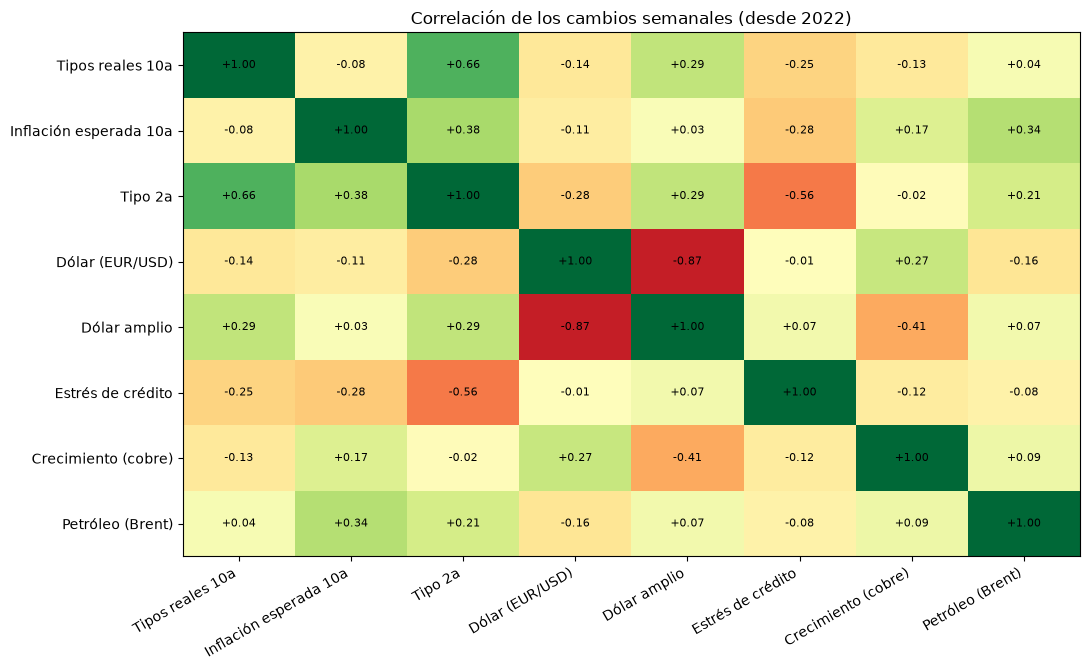

In [3]:
def mapa(M, T, titulo, escala=100, fmt="{:+.2f}"):
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(M) + 2))
    v = np.nanmax(np.abs(M.values)) * escala
    ax.imshow(M.values * escala, cmap="RdYlGn", vmin=-v, vmax=v, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            t = T.iloc[i, j] if T is not None else 0
            marca = "**" if abs(t) > 2.58 else "*" if abs(t) > 1.96 else ""
            ax.text(j, i, fmt.format(M.iloc[i, j] * escala) + marca, ha="center", va="center", fontsize=8)
    ax.set_xticks(range(M.shape[1]), M.columns, rotation=30, ha="right")
    ax.set_yticks(range(M.shape[0]), M.index)
    ax.set_title(titulo)
    fig.tight_layout()


corr_total = z.corr()
corr_actual = z.loc[CORTE_REGIMEN:].corr()
mapa(corr_actual, None, f"Correlación de los cambios semanales (desde {CORTE_REGIMEN[:4]})", escala=1)

## Estimación
Para cada activo y periodo: regresión múltiple (exposición directa) y regresiones simples (efecto típico).

In [4]:
def estimar(desde=None, hasta=None):
    """Devuelve (beta, t_beta, gamma, t_gamma, R² múltiple) por activo."""
    B, TB, G, TG, R2 = {}, {}, {}, {}, {}
    Z = z.loc[desde:hasta]
    for activo in rent.columns:
        y = rent[activo].loc[desde:hasta]
        b, t, r2, n = mco(y, Z)
        B[activo], TB[activo], R2[activo] = b, t, {"R²": r2, "semanas": n}
        g, tg = {}, {}
        for v in Z.columns:
            gv, tv, _, _ = mco(y, Z[[v]])
            g[v], tg[v] = gv[v], tv[v]
        G[activo], TG[activo] = pd.Series(g), pd.Series(tg)
    f = lambda d: pd.DataFrame(d).T
    return f(B), f(TB), f(G), f(TG), f(R2)


periodos = {"completo": (None, None), "antes": (None, CORTE_REGIMEN), "actual": (CORTE_REGIMEN, None)}
est = {k: estimar(*v) for k, v in periodos.items()}
print("R² de la regresión múltiple:")
print(pd.concat({k: e[4]["R²"] for k, e in est.items()}, axis=1).round(2).to_string())

R² de la regresión múltiple:
                      completo  antes  actual
Vanguard U.S. 500         0.46   0.55    0.36
Amundi MSCI World         0.47   0.56    0.39
Fidelity Global Tech      0.31   0.42    0.23
Russell 2000 (ZPRR)       0.41   0.50    0.34
Bono EE. UU. 2035         0.99   0.99    0.99
ETH                       0.09   0.10    0.10
BTC (WBTC)                0.04   0.04    0.08
VanEck Rare Earth         0.34   0.38    0.34


Vanguard U.S. 500: máx |γ − Σβρ| = 0.0018 puntos


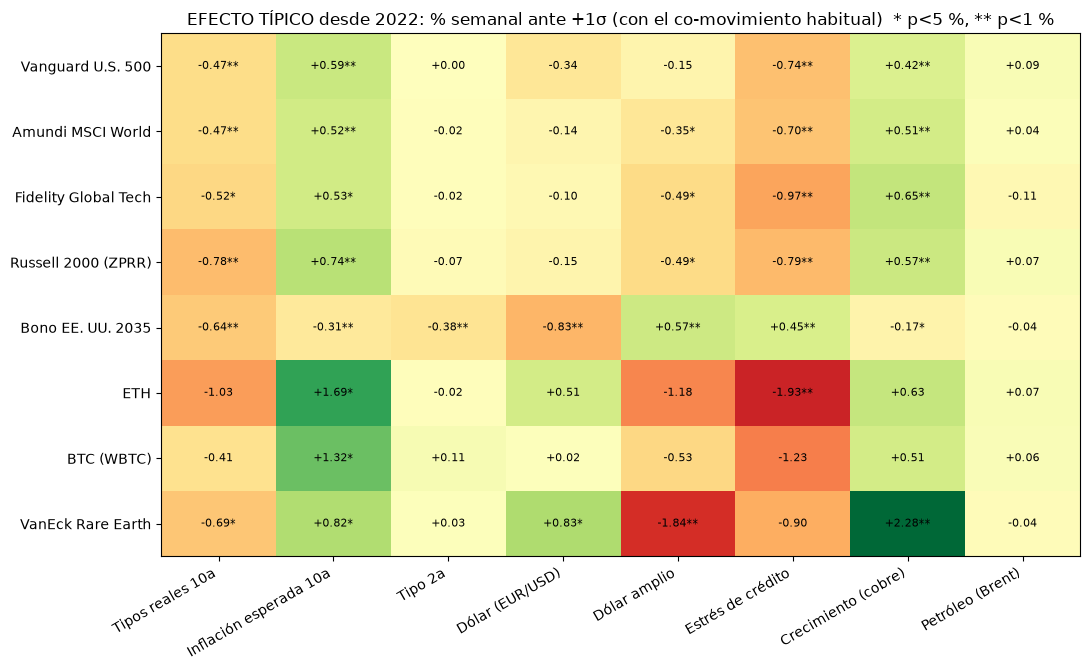

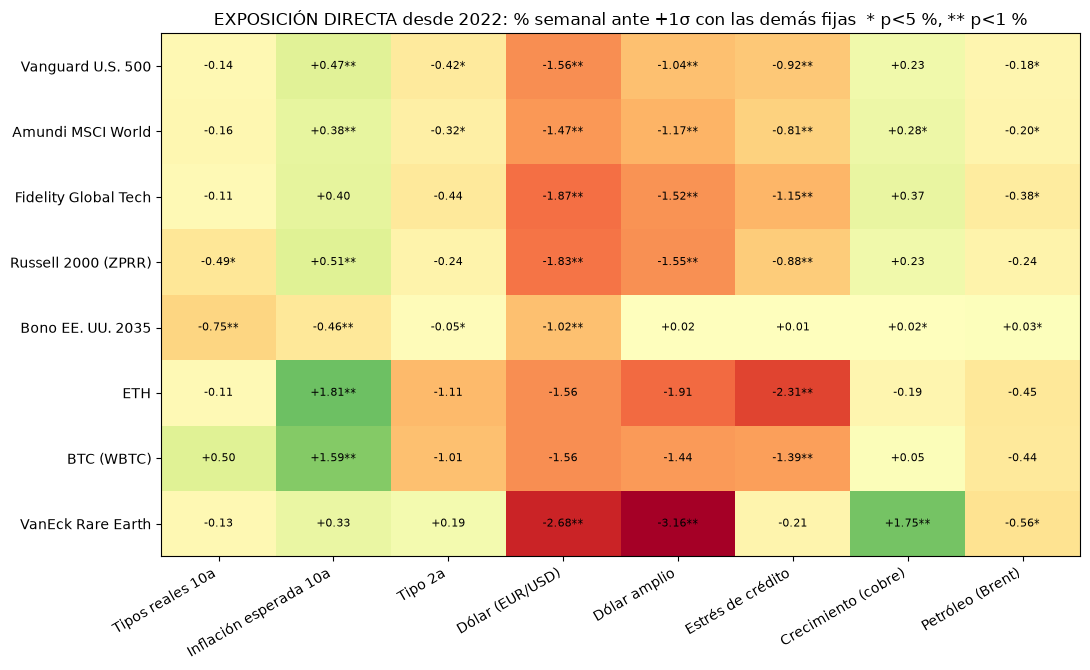

In [5]:
B, TB, G, TG, _ = est["actual"]
mapa(G, TG, f"EFECTO TÍPICO desde {CORTE_REGIMEN[:4]}: % semanal ante +1σ (con el co-movimiento habitual)  * p<5 %, ** p<1 %")
mapa(B, TB, f"EXPOSICIÓN DIRECTA desde {CORTE_REGIMEN[:4]}: % semanal ante +1σ con las demás fijas  * p<5 %, ** p<1 %")

# Comprobación de la identidad gamma = R · beta (con la covarianza de la muestra; debe cuadrar casi exacto)
Zs = z.loc[CORTE_REGIMEN:]
for activo in ["Vanguard U.S. 500"]:
    datos_ok = pd.concat([rent[activo], Zs], axis=1).loc[CORTE_REGIMEN:].dropna()
    C = datos_ok[Zs.columns].cov()
    implicito = (C @ B.loc[activo]) / np.diag(C)
    print(f"{activo}: máx |γ − Σβρ| = {np.abs(implicito - G.loc[activo]).max() * 100:.4f} puntos")

## Estabilidad por régimen
Se marca como inestable una relación que es significativa al 5 % en algún periodo y cambia de signo entre periodos.

In [6]:
def cambia_signo(M1, T1, M2, T2):
    return (np.sign(M1) != np.sign(M2)) & ((T1.abs() > 1.96) | (T2.abs() > 1.96))


B1, TB1, G1, TG1, _ = est["antes"]
inestable_g = cambia_signo(G1, TG1, G, TG)
inestable_b = cambia_signo(B1, TB1, B, TB)
for nombre, M1, M2, mask in [("Efecto típico", G1, G, inestable_g), ("Exposición directa", B1, B, inestable_b)]:
    print(f"\n{nombre}: relaciones que cambian de signo")
    for a, v in zip(*np.where(mask)):
        print(f"  {M2.index[a]} — {M2.columns[v]}: {M1.iloc[a, v]*100:+.2f} → {M2.iloc[a, v]*100:+.2f}")


Efecto típico: relaciones que cambian de signo
  Vanguard U.S. 500 — Tipos reales 10a: +0.21 → -0.47
  Amundi MSCI World — Tipos reales 10a: +0.07 → -0.47
  Amundi MSCI World — Tipo 2a: +1.32 → -0.02
  Fidelity Global Tech — Tipos reales 10a: +0.27 → -0.52
  Fidelity Global Tech — Tipo 2a: +1.41 → -0.02
  Fidelity Global Tech — Petróleo (Brent): +0.70 → -0.11
  Russell 2000 (ZPRR) — Tipos reales 10a: +0.20 → -0.78
  Russell 2000 (ZPRR) — Tipo 2a: +1.65 → -0.07
  VanEck Rare Earth — Tipos reales 10a: +0.14 → -0.69
  VanEck Rare Earth — Dólar (EUR/USD): -0.06 → +0.83
  VanEck Rare Earth — Petróleo (Brent): +1.46 → -0.04

Exposición directa: relaciones que cambian de signo
  Vanguard U.S. 500 — Tipo 2a: +0.28 → -0.42
  Amundi MSCI World — Tipo 2a: +0.43 → -0.32
  Russell 2000 (ZPRR) — Tipos reales 10a: +0.42 → -0.49
  Bono EE. UU. 2035 — Crecimiento (cobre): -0.03 → +0.02
  BTC (WBTC) — Petróleo (Brent): +0.96 → -0.44
  VanEck Rare Earth — Petróleo (Brent): +0.25 → -0.56


## Guardar la matriz
Columnas: `efecto_*` (efecto típico) y `parcial_*` (exposición directa), del periodo completo y del régimen actual, con su t. `lectura` resume el efecto típico del régimen actual (0 = no significativo al 1 %); `lectura_parcial`, la exposición directa. `estable` se refiere al efecto típico.

In [7]:
def lectura(b, t):
    if abs(t) < UMBRAL_T:
        return "0"
    fuerza = abs(b) * 100
    return ("+" if b > 0 else "−") * (3 if fuerza >= 1 else 2 if fuerza >= 0.4 else 1)


Bc, TBc, Gc, TGc, _ = est["completo"]
filas = []
for activo in B.index:
    for var in B.columns:
        filas.append({
            "activo": activo, "variable": var,
            "efecto_actual": G.loc[activo, var], "t_efecto_actual": TG.loc[activo, var],
            "efecto_completo": Gc.loc[activo, var], "t_efecto_completo": TGc.loc[activo, var],
            "parcial_actual": B.loc[activo, var], "t_parcial_actual": TB.loc[activo, var],
            "parcial_completo": Bc.loc[activo, var], "t_parcial_completo": TBc.loc[activo, var],
            "lectura": lectura(G.loc[activo, var], TG.loc[activo, var]),
            "lectura_parcial": lectura(B.loc[activo, var], TB.loc[activo, var]),
            "estable": not inestable_g.loc[activo, var],
        })
salida = pd.DataFrame(filas)
salida.insert(0, "fecha", date.today().isoformat())
salida.to_csv(FICHERO_MATRIZ, index=False, float_format="%.5f")
print(f"Guardada en {FICHERO_MATRIZ} ({len(salida)} filas)\n")
for col, titulo in [("lectura", "EFECTO TÍPICO"), ("lectura_parcial", "EXPOSICIÓN DIRECTA")]:
    print(f"{titulo} (régimen actual; 0 = no significativo al 1 %):")
    print(salida.pivot(index="activo", columns="variable", values=col).to_string(), "\n")

Guardada en /Users/iyantp_/Finanzas/analisis/exposiciones.csv (64 filas)

EFECTO TÍPICO (régimen actual; 0 = no significativo al 1 %):
variable             Crecimiento (cobre) Dólar (EUR/USD) Dólar amplio Estrés de crédito Inflación esperada 10a Petróleo (Brent) Tipo 2a Tipos reales 10a
activo                                                                                                                                                  
Amundi MSCI World                     ++               0            0                −−                     ++                0       0               −−
BTC (WBTC)                             0               0            0                 0                      0                0       0                0
Bono EE. UU. 2035                      0              −−           ++                ++                      −                0       −               −−
ETH                                    0               0            0               −−−             

## Comprobación de la cesta diaria del dólar
El resumen diario aproxima el dólar amplio (FRED DTWEXBGS, con una semana de retraso) con `universo.CESTA_DOLAR`. Aquí se comprueba que la aproximación sigue al índice de la Fed (correlación semanal esperada > 0,9).

In [8]:
from nucleo.datos import alinear_fx, _cierres
from nucleo.universo import CESTA_DOLAR

try:
    cesta = sum(w * np.log(alinear_fx(_cierres(t, "max"))).diff() for t, w in CESTA_DOLAR.items())
    cesta = semanal(cesta.dropna().cumsum()).diff().loc[INICIO:]
    print(f"Correlación semanal cesta vs DTWEXBGS: {cesta.corr(cambios['Dólar amplio']):.2f}")
except Exception as e:
    print(f"No se pudo comprobar la cesta: {e}")

/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
/Use

Correlación semanal cesta vs DTWEXBGS: 0.93


/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
/Use